<a href="https://colab.research.google.com/github/laboralit82-lab/ProcesamientoDelHabla/blob/main/MALIZIA_MARIELA_PH_TP_PDF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo práctico: Análisis de documentos PDF con Python

## Inteligencia artificial aplicada a la práctica psicológica

**Artículo seleccionado:** La IA en la Práctica Psicológica: ¿qué Existe y Cómo Puede Ayudar en Psicología Asistencial?

**Autores:** Daniel de la Fuente Tambo y Manuel Armayones Ruiz.

**Fuente:** Revista Papeles del Psicólogo (2025).

### Objetivo

El objetivo de este trabajo es analizar un artículo científico sobre las aplicaciones de la inteligencia artificial en la práctica psicológica.

Para ello, se utilizarán herramientas de Python que permitan descargar el documento, explorar sus metadatos, extraer información textual y tabular y analizar la frecuencia de palabras.

## Índice

1. Adquisición del documento y metadatos
2. Análisis estructural del texto
3. Extracción y procesamiento de tablas
4. Procesamiento del Lenguaje Natural (NLP)
5. Conclusión general
6. Referencias bibliográficas y herramientas utilizadas

## 1. Adquisición del documento y metadatos

En esta primera etapa se descargará un artículo científico sobre inteligencia artificial aplicada a la práctica psicológica.

Para realizar la descarga se utilizará la biblioteca requests de Python. Luego se analizarán los metadatos del archivo PDF.

In [14]:
# Importamos la biblioteca requests
import requests

# Dirección del PDF original de la revista
url = "https://www.papelesdelpsicologo.es/pdf/3050.pdf"

# Descargamos el documento
respuesta = requests.get(url, timeout=30)
respuesta.raise_for_status()

# Comprobamos que sea un PDF
if respuesta.content[:4] == b"%PDF":

    # Guardamos el archivo
    with open("articulo_ia_psicologia.pdf", "wb") as archivo:
        archivo.write(respuesta.content)

    print("PDF descargado correctamente")
    print("Tamaño:", len(respuesta.content), "bytes")

else:
    print("El archivo descargado no es un PDF")

PDF descargado correctamente
Tamaño: 482305 bytes


In [15]:
# Instalamos la biblioteca PyMuPDF
!pip install -q pymupdf

# Importamos la biblioteca
import pymupdf

# Abrimos el PDF descargado
documento = pymupdf.open("articulo_ia_psicologia.pdf")

# Obtenemos los metadatos
metadatos = documento.metadata

# Mostramos los resultados
print("Título:", metadatos.get("title"))
print("Autor:", metadatos.get("author"))
print("Cantidad de páginas:", len(documento))
print("Software de creación:", metadatos.get("creator"))

Título: 
Autor: 
Cantidad de páginas: 7
Software de creación: Adobe InDesign 16.0 (Macintosh)


### Interpretación de los metadatos

El documento contiene 7 páginas y fue creado utilizando Adobe InDesign 16.0 (Macintosh).

Los campos correspondientes al título y al autor aparecen vacíos en los metadatos del archivo. Esto indica que dicha información no fue incorporada a las propiedades técnicas del PDF, aunque puede encontrarse en el contenido del artículo.

La biblioteca PyMuPDF permitió recuperar correctamente la información disponible.

## 2. Análisis estructural del texto

En esta etapa se extraerá el texto de las primeras cinco páginas del documento PDF para observar cómo Python recupera su contenido.

In [16]:
# Extraemos el texto de las primeras cinco páginas del PDF

texto_crudo = ""

for numero_pagina in range(5):
    pagina = documento[numero_pagina]
    texto_crudo += pagina.get_text()

# Mostramos los primeros 2000 caracteres
print(texto_crudo[:2000])

Papeles del Psicólogo 
Psychologist Papers
Papeles del Psicólogo (2025) 46(1) 18-24
Artículo
Revista del Consejo General de la Psicología de España
https://www.papelesdelpsicologo.es/ • ISSN 0214–7823 • eISSN 1886–1415
La IA en la Práctica Psicológica: ¿qué Existe y Cómo Puede Ayudar  
en Psicología Asistencial?
Daniel de la Fuente Tambo  y Manuel Armayones Ruiz 
Universitat Oberta de Catalunya, España
INFORMACIÓN
ABSTRACT
Recibido: Noviembre 11, 2024
Aceptado: Diciembre 2, 2024
Keywords
Artificial intelligence
Tools of AI in therapy
Adoptions of AI in psychology
Privacy of information
This article reviews the use of Artificial Intelligence (AI) in the field of Clinical Psychology, evaluating tools that 
support psychology professionals in their daily work. A market analysis of AI-based products currently available 
was conducted, from which 12 were selected for a more detailed evaluation. The results show that, although not 
all tools meet strict criteria for security and scientific e

In [17]:
# Analizamos los separadores presentes en el texto extraído

print("Cantidad de caracteres:", len(texto_crudo))
print("Saltos de línea (\\n):", texto_crudo.count("\n"))
print("Retornos de carro (\\r):", texto_crudo.count("\r"))
print("Tabulaciones (\\t):", texto_crudo.count("\t"))
print("Espacios:", texto_crudo.count(" "))

Cantidad de caracteres: 26326
Saltos de línea (\n): 658
Retornos de carro (\r): 0
Tabulaciones (\t): 0
Espacios: 3665


### Interpretación del análisis estructural

La extracción de las primeras cinco páginas permitió recuperar un total de 26.326 caracteres.

Se identificaron 658 saltos de línea y 3.665 espacios, mientras que no se encontraron retornos de carro ni tabulaciones.

Estos resultados muestran que el texto conserva separadores que permiten reconocer parte de su organización original.

Sin embargo, los saltos de línea no necesariamente representan cambios de párrafo, ya que también pueden responder a la distribución visual del contenido dentro del PDF.

Por este motivo, resulta necesario analizar la estructura del texto antes de aplicar técnicas de limpieza y procesamiento del lenguaje natural.

In [18]:
# Dividimos el texto utilizando los saltos de línea
lineas = texto_crudo.split("\n")

# Contamos las líneas obtenidas
print("Cantidad de segmentos:", len(lineas))

# Mostramos las primeras 30 líneas
for numero, linea in enumerate(lineas[:30], start=1):
    print(numero, ":", linea)

Cantidad de segmentos: 659
1 : Papeles del Psicólogo 
2 : Psychologist Papers
3 : Papeles del Psicólogo (2025) 46(1) 18-24
4 : Artículo
5 : Revista del Consejo General de la Psicología de España
6 : https://www.papelesdelpsicologo.es/ • ISSN 0214–7823 • eISSN 1886–1415
7 : La IA en la Práctica Psicológica: ¿qué Existe y Cómo Puede Ayudar  
8 : en Psicología Asistencial?
9 : Daniel de la Fuente Tambo  y Manuel Armayones Ruiz 
10 : Universitat Oberta de Catalunya, España
11 : INFORMACIÓN
12 : ABSTRACT
13 : Recibido: Noviembre 11, 2024
14 : Aceptado: Diciembre 2, 2024
15 : Keywords
16 : Artificial intelligence
17 : Tools of AI in therapy
18 : Adoptions of AI in psychology
19 : Privacy of information
20 : This article reviews the use of Artificial Intelligence (AI) in the field of Clinical Psychology, evaluating tools that 
21 : support psychology professionals in their daily work. A market analysis of AI-based products currently available 
22 : was conducted, from which 12 were selected f

### Identificación de párrafos y secciones

Al dividir el texto mediante los saltos de línea se obtuvieron 659 segmentos.

La exploración de los primeros segmentos permitió identificar información bibliográfica, el título del artículo, sus autores y encabezados como INFORMACIÓN, ABSTRACT y RESUMEN.

También se observó que algunos elementos, como el título y el resumen, aparecen divididos en varias líneas.

Esto permite concluir que los saltos de línea no siempre representan cambios de párrafo. En muchos casos responden a la diagramación original del PDF.

Por lo tanto, para realizar un análisis del lenguaje es importante considerar estas características y aplicar procedimientos de limpieza que permitan trabajar con el contenido textual.

## 3. Extracción y procesamiento de tablas

En esta etapa se identificarán las tablas presentes en el artículo científico.

Posteriormente, se utilizará la biblioteca Pandas para organizar los datos extraídos y realizar las tareas de limpieza necesarias.

In [19]:
# Instalamos e importamos pdfplumber
!pip install -q pdfplumber
import pdfplumber

# Abrimos el PDF y seleccionamos la tercera página
with pdfplumber.open("articulo_ia_psicologia.pdf") as pdf:
    pagina = pdf.pages[2]

    # Seleccionamos la mitad izquierda, sin el pie de página
    zona_tabla = pagina.crop(
        (0, 0, pagina.width / 2, pagina.height - 50)
    )

    # Configuramos la extracción de la tabla
    configuracion = {
        "vertical_strategy": "text",
        "horizontal_strategy": "lines",
        "intersection_tolerance": 5
    }

    tablas_detectadas = zona_tabla.extract_tables(
        table_settings=configuracion
    )

    print("Tablas detectadas:", len(tablas_detectadas))

Tablas detectadas: 1


In [20]:
# Importamos la biblioteca Pandas
import pandas as pd

# Convertimos la tabla extraída en un DataFrame
df = pd.DataFrame(tablas_detectadas[0])

# Mostramos las primeras filas
display(df.head())

,0,1,2,3,4,5
0,Herramienta,País,,Desc,ripción,
1,Aimentia,España,,Plataforma de salud m\napoyar a profesionales\...,ental que usa IA para\ny pacientes en el\nto y...,
2,Cass,Estados Un,idos,Asistente de bienestar\nIA para ofrecer apoyo\...,mental que utiliza\nmediante mensajes\nesgo co...,
3,Censeo,Reino Unid,o,Herramienta basada en\ny tratar varios trastor...,"IAG para evaluar\nos como DEP, TAG,\npsicólogo...",
4,Eholo,España,,Plataforma para psicól\nun sistema integral pa...,"ogos que ofrece\na gestionar la\na, documentac...",


In [21]:
# Organizamos los datos en tres columnas
df_limpio = pd.DataFrame({
    "Herramienta": df.iloc[1:, 0],
    "País": df.iloc[1:, 1].fillna("") + df.iloc[1:, 2].fillna(""),
    "Descripción": (
        df.iloc[1:, 3].fillna("") +
        df.iloc[1:, 4].fillna("") +
        df.iloc[1:, 5].fillna("")
    )
})

# Eliminamos las filas completamente vacías
df_limpio = df_limpio.replace(r"^\s*$", pd.NA, regex=True)
df_limpio = df_limpio.dropna(how="all")

# Mostramos el resultado
display(df_limpio.head())

,Herramienta,País,Descripción
1,Aimentia,España,Plataforma de salud m\napoyar a profesionales\...
2,Cass,Estados Unidos,Asistente de bienestar\nIA para ofrecer apoyo\...
3,Censeo,Reino Unido,Herramienta basada en\ny tratar varios trastor...
4,Eholo,España,Plataforma para psicól\nun sistema integral pa...
5,Jobot,Australia,Chatbot basado en IA\npsicológico personaliz\n...


In [22]:
# Limpieza final de la tabla

# Reemplazamos los saltos de línea por espacios
df_limpio["Descripción"] = (
    df_limpio["Descripción"]
    .str.replace("\n", " ", regex=False)
)

# Reiniciamos la numeración de las filas
df_limpio = df_limpio.reset_index(drop=True)

# Mostramos la tabla limpia
display(df_limpio.head())

,Herramienta,País,Descripción
0,Aimentia,España,Plataforma de salud m apoyar a profesionales d...
1,Cass,Estados Unidos,Asistente de bienestar IA para ofrecer apoyo d...
2,Censeo,Reino Unido,Herramienta basada en y tratar varios trastorn...
3,Eholo,España,Plataforma para psicól un sistema integral par...
4,Jobot,Australia,Chatbot basado en IA psicológico personaliz TC...


### Resultado de la extracción y limpieza

Se extrajo la Tabla 1 del artículo, correspondiente a las herramientas de inteligencia artificial utilizadas en psicología.

Mediante Pandas, se organizaron los datos en tres columnas: Herramienta, País y Descripción.

Se realizó una limpieza básica para eliminar filas vacías, reemplazar saltos de línea y reorganizar los datos.

Se observaron algunas palabras fragmentadas en las descripciones debido a la diagramación del PDF, lo que constituye una limitación de la extracción automática.

## 4. Procesamiento del Lenguaje Natural (NLP)

En esta etapa se seleccionará una página del artículo que contenga texto narrativo para realizar un análisis mediante técnicas de procesamiento del lenguaje natural.

Se utilizará la biblioteca NLTK para tokenizar el texto, convertirlo a minúsculas y eliminar palabras vacías (stopwords) y signos de puntuación.

Finalmente, se identificarán y representarán gráficamente las 15 palabras más frecuentes.

In [23]:
# Seleccionamos una página del artículo para analizar

!pip install -q pymupdf
import pymupdf

documento = pymupdf.open("articulo_ia_psicologia.pdf")

# Seleccionamos la cuarta página del PDF
pagina = documento[3]

# Extraemos su texto
texto_pagina = pagina.get_text()

# Mostramos los primeros 1000 caracteres
print(texto_pagina[:1000])

La IA en la Práctica Psicológica
21
Número de Clientes Actuales
El análisis revela que, a fecha actual, muchas de estas soluciones 
están logrando un amplio uso de las mismas en profesionales y 
pacientes. Según se muestra en la Tabla 3, la antigüedad y el número 
de usuarios que utilizan cada herramienta varía según el rol que 
desempeñan, pero a nivel general va en aumento.
En el rol administrativo, por ejemplo Eholo, un producto 
español cuenta con más de 10,000 psicólogos que lo están 
utilizando, lo cual indica una buena aceptación entre profesionales 
que buscan optimizar la parte organizativa de su práctica. Por otro 
lado, las herramientas en el rol de ayudante del psicólogo, como 
Censeo y Limbic, también tienen una amplia adopción. Limbic está 
implantada en aproximadamente el 40% de las clínicas del NHS 
en el Reino Unido, lo que demuestra su alto impacto. Estas 
herramientas están diseñadas específicamente para apoyar al 
terapeuta en la evaluación y seguimiento de los paci

In [24]:
# Instalamos e importamos NLTK
!pip install -q nltk

import nltk
from nltk.tokenize import word_tokenize

# Descargamos los recursos necesarios
nltk.download("punkt")
nltk.download("punkt_tab")

# Convertimos el texto a minúsculas
texto_minusculas = texto_pagina.lower()

# Dividimos el texto en palabras (tokenización)
tokens = word_tokenize(texto_minusculas, language="spanish")

# Mostramos los primeros 30 tokens
print(tokens[:30])

['la', 'ia', 'en', 'la', 'práctica', 'psicológica', '21', 'número', 'de', 'clientes', 'actuales', 'el', 'análisis', 'revela', 'que', ',', 'a', 'fecha', 'actual', ',', 'muchas', 'de', 'estas', 'soluciones', 'están', 'logrando', 'un', 'amplio', 'uso', 'de']


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [25]:
# Importamos las stopwords de NLTK
from nltk.corpus import stopwords
import string

# Descargamos las stopwords en español
nltk.download("stopwords")

# Creamos la lista de palabras vacías
palabras_vacias = set(stopwords.words("spanish"))

# Eliminamos stopwords y signos de puntuación
tokens_limpios = [
    palabra for palabra in tokens
    if palabra not in palabras_vacias
    and palabra not in string.punctuation
    and palabra.isalpha()
]

# Comparamos los resultados
print("Tokens originales:", len(tokens))
print("Tokens después de la limpieza:", len(tokens_limpios))
print("\nPrimeros 30 tokens limpios:")
print(tokens_limpios[:30])

Tokens originales: 941
Tokens después de la limpieza: 429

Primeros 30 tokens limpios:
['ia', 'práctica', 'psicológica', 'número', 'clientes', 'actuales', 'análisis', 'revela', 'fecha', 'actual', 'muchas', 'soluciones', 'logrando', 'amplio', 'uso', 'mismas', 'profesionales', 'pacientes', 'según', 'muestra', 'tabla', 'antigüedad', 'número', 'usuarios', 'utilizan', 'cada', 'herramienta', 'varía', 'según', 'rol']


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


[('si', 13), ('herramientas', 11), ('rol', 9), ('información', 9), ('herramienta', 7), ('pacientes', 6), ('cada', 6), ('seguimiento', 6), ('ia', 5), ('usuarios', 5), ('limbic', 5), ('datos', 5), ('seguridad', 5), ('privacidad', 5), ('práctica', 4)]


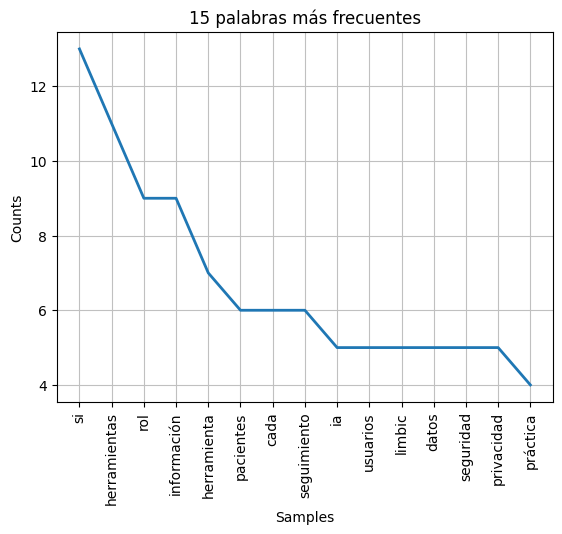

In [26]:
# Calculamos la frecuencia de las palabras
from nltk.probability import FreqDist
import matplotlib.pyplot as plt

frecuencias = FreqDist(tokens_limpios)

# Mostramos las 15 palabras más frecuentes
print(frecuencias.most_common(15))

# Generamos el gráfico
frecuencias.plot(15, title="15 palabras más frecuentes")
plt.show()

### Interpretación de las frecuencias

El análisis permitió identificar las 15 palabras más frecuentes de la página seleccionada.

Entre los términos destacados aparecen herramientas, rol, información, pacientes, seguimiento, usuarios, seguridad y privacidad. Estas palabras se relacionan con el contenido del artículo, centrado en la aplicación de la inteligencia artificial en la práctica psicológica.

También se observó que la palabra "si" presenta la frecuencia más elevada. Esto demuestra que, aun después de eliminar las stopwords mediante NLTK, pueden permanecer términos poco relevantes para el análisis.

Por otra parte, las palabras "herramienta" y "herramientas" se contabilizan por separado, ya que no se aplicaron procedimientos de lematización.

En conclusión, el procesamiento permitió reconocer términos representativos del documento y comprender algunas limitaciones de la limpieza automática del lenguaje.

## 5. Conclusión general

Este trabajo permitió explorar distintas herramientas de Python para analizar un artículo científico sobre inteligencia artificial aplicada a la práctica psicológica.

Mediante requests se descargó el documento y con PyMuPDF se analizaron sus metadatos y se extrajo su contenido textual.

El análisis estructural permitió observar que los saltos de línea del PDF no siempre corresponden a párrafos completos.

Con pdfplumber y Pandas se extrajo y organizó una tabla del artículo, aunque se identificaron algunas dificultades relacionadas con su diagramación original.

Finalmente, mediante NLTK se realizó la tokenización, la eliminación de palabras vacías y el análisis de las quince palabras más frecuentes.

En conclusión, estas herramientas permiten automatizar el análisis de documentos, aunque los resultados requieren una revisión para identificar posibles errores de extracción y limpieza.

## 6. Referencias y uso de inteligencia artificial
## 6. Referencias y uso de inteligencia artificial

### 6.1. Artículo científico utilizado

De la Fuente Tambo, D., y Armayones Ruiz, M. (2025). *La IA en la práctica psicológica: ¿qué existe y cómo puede ayudar en psicología asistencial?* Papeles del Psicólogo, 46(1), 18-24.

Fuente: https://www.papelesdelpsicologo.es/pdf/3050.pdf

### 6.2. Herramientas y bibliotecas utilizadas

Para el desarrollo de este trabajo se utilizó Python en Google Colab, junto con las siguientes bibliotecas:

* **Requests:** descarga automatizada del artículo científico.
* **PyMuPDF:** lectura del PDF, consulta de metadatos y extracción de texto.
* **pdfplumber:** identificación y extracción de información tabular.
* **Pandas:** organización y limpieza de los datos mediante DataFrames.
* **NLTK:** tokenización, eliminación de palabras vacías y análisis de frecuencias.
* **Matplotlib:** representación gráfica de las palabras más frecuentes.

### 6.3. Utilización de inteligencia artificial durante el desarrollo

Durante la realización del trabajo práctico utilicé ChatGPT como herramienta de apoyo para comprender el funcionamiento de las bibliotecas de Python, analizar los resultados obtenidos y resolver dificultades relacionadas con el procesamiento del documento.

La interacción con la inteligencia artificial se desarrolló principalmente en las siguientes etapas:

**1. Adquisición del documento y metadatos**

Se utilizó ChatGPT para comprender cómo descargar un archivo PDF mediante Requests y cómo acceder a sus propiedades técnicas utilizando PyMuPDF.

También se trabajó sobre la interpretación de los campos de metadatos que aparecían vacíos, diferenciando la información disponible en las propiedades del archivo de aquella presente en el contenido del artículo.

**2. Análisis estructural del texto**

Se consultó sobre el funcionamiento de `get_text()` y sobre los caracteres que permiten identificar separaciones dentro del texto extraído.

Se analizaron especialmente los saltos de línea (`\n`), los espacios y la diferencia entre la estructura visual de un documento PDF y su representación como texto.

**3. Extracción y limpieza de tablas**

Se utilizó ChatGPT para comprender el procedimiento de extracción de tablas mediante pdfplumber y su posterior conversión en un DataFrame de Pandas.

Una de las principales dificultades fue que la estructura de la tabla no se recuperó exactamente como aparecía en el documento original. Por este motivo, fue necesario reorganizar columnas, eliminar filas vacías y realizar ajustes sobre el texto extraído.

**4. Procesamiento del Lenguaje Natural**

Se trabajó en la comprensión de la tokenización, la conversión a minúsculas y la eliminación de stopwords y signos de puntuación.

También se analizó la interpretación del gráfico de frecuencias y la permanencia de algunas palabras poco relevantes después de la limpieza.

**5. Interpretación y conclusiones**

ChatGPT se utilizó como apoyo para organizar las explicaciones de cada apartado y revisar la interpretación de los resultados.

El análisis permitió reconocer tanto las posibilidades de automatización que ofrecen estas herramientas como sus limitaciones, especialmente cuando los documentos presentan estructuras complejas.

### 6.4. Reflexión sobre el uso de inteligencia artificial

La utilización de ChatGPT facilitó el proceso de aprendizaje, especialmente para comprender instrucciones de Python y relacionar los resultados obtenidos con los objetivos de cada actividad.

Sin embargo, el desarrollo del trabajo también permitió reconocer la importancia de revisar las respuestas generadas por inteligencia artificial, ejecutar el código y comprobar que los resultados correspondan efectivamente al documento analizado.

La experiencia permitió comprender que estas herramientas pueden funcionar como recursos de apoyo para el aprendizaje y la resolución de problemas, pero que su utilización requiere análisis, criterio propio y verificación de los resultados.

### 6.5. Registro de interacción con ChatGPT

Herramienta utilizada: ChatGPT, de OpenAI.

Finalidad: asistencia en la comprensión del código


